In [1]:
import numpy as np
import pandas as pd
from scipy.special import comb
import matplotlib.pyplot as plt
from tabulate import tabulate

In [2]:
class CallOptionSequence:
    def __init__(self, s0, epsilon, N):
        self.s0 = s0
        self.epsilon = epsilon
        self.N = N

    def generate_sequence(self):
        y = np.zeros(self.N + 1)
        y[1] = self.s0
        for i in range(2, self.N + 1):
            y[i] = y[i - 1] + np.random.randint(-self.epsilon, self.epsilon)
        return y

    def prob_indicator_gt(self, n, v):
        # calculate probability that y_{N-n+1}>v
        p = (self.s0 + (self.N - n) * self.epsilon - v) / (2 * self.epsilon + 1)
        p = min(1, max(0, p))
        return p

In [3]:
def compute_sequences(y, N):
    # Initialize V_m1,m2, V_m1, and X_m1
    Vm1_m2 = np.zeros((N, N))
    Vm = np.zeros(N)
    Xm = np.zeros(N)

    # Backward induction to compute Vm1,m2
    for m1 in range(N - 1, -1, -1):
        for m2 in range(m1 + 1, N):
            if m2 == N - 1:
                Vm1_m2[m1, m2] = y[m2] - y[m1]
            else:
                Vm1_m2[m1, m2] = max(y[m2] - y[m1], np.mean(Vm1_m2[m1, m2 + 1]))

    # Compute Xm1 using its recursive formula
    for m1 in range(N - 1, -1, -1):
        if m1 < N - 1:
            Xm[m1] = np.mean(Vm1_m2[m1, m1 + 1])

    # Compute Vm1 using its recursive formula
    for m1 in range(N - 1, -1, -1):
        if m1 < N - 1:
            Vm[m1] = max(Xm[m1], np.mean(Vm[m1 + 1]))
        else:
            Vm[m1] = Xm[m1]

    return Xm, Vm, Vm1_m2

In [4]:
# N = 10
# y = generate_sequence(10, 2, 10)
# Xm, Vm, Vm1_m2 = compute_sequences(y, N)
seq = CallOptionSequence(10, 2, 10)

In [5]:
# # Theorem 1
# import numpy as np


# def compute_v_values(N):
#     v = np.zeros((N + 1, 3))  # Indexing: v[n, 1] = vN-n,1 and v[n, 2] = vN-n,2

#     v[1, 2] = 0
#     v[0, 1] = -np.inf
#     for n in range(1, N):
#         p1 = seq.prob_indicator_gt(n, v[n - 1, 1])
#         if n == 1:
#             v[n, 1] = seq.s0 * p1
#         else:
#             v[n, 1] = seq.s0 * p1 + v[n - 1, 1] * (1 - p1)
#     for n in range(2, N + 1):
#         p2 = 1 - seq.prob_indicator_gt(n, v[n - 1, 1] - v[n - 1, 2])
#         v[n, 2] = (v[n - 1, 1] - seq.s0) * p2 + v[n - 1, 2] * (1 - p2)

#     return v[:, 1], v[:, 2]


# def find_optimal_stopping(y_values):
#     N = len(y_values)
#     vN_1, vN_2 = compute_v_values(N)
#     τ1 = N
#     for m1 in range(1, N):
#         if y_values[m1] <= vN_1[N - m1] - vN_2[N - m1]:
#             τ1 = m1
#             break

#     τ2 = N + 1
#     for m2 in range(τ1 + 1, N + 1):
#         if y_values[m2] >= vN_1[N - m2]:
#             τ2 = m2
#             break

#     return τ1, τ2


# # Example usage
# y_values = seq.generate_sequence()
# τ1, τ2 = find_optimal_stopping(y_values)

# print(f"Optimal stopping times: Buy at t={τ1}, Sell at t={τ2}")

In [6]:
# print("\nObserved sequence (y values):")
# print(pd.DataFrame(y, columns=["y"]))

# print("\nXm1 values:")
# print(pd.DataFrame(Xm, columns=["Xm1"]))

# print("\nVm1 values:")
# print(pd.DataFrame(Vm, columns=["Vm1"]))

# print("\nVm1,m2 values:")
# df = pd.DataFrame(
#     Vm1_m2, index=[f"m1={i}" for i in range(N)], columns=[f"m2={i}" for i in range(N)]
# )
# mask = np.tril(np.ones_like(Vm1_m2, dtype=bool))
# df = df.mask(mask, "")
# print(df)

In [7]:
class GeometricRandomWalk:
    def __init__(self, y_0, p, lambda_, N):
        self.y_0 = y_0
        self.p = p
        self.N = N
        self.lambda_ = lambda_

    def generate_sequence(self):
        y = np.zeros(self.N + 1)
        y[1] = self.y_0
        for i in range(2, self.N + 1):
            y[i] = y[i - 1] * (
                self.lambda_ ** np.random.choice([-1, 1], p=[1 - self.p, self.p])
            )
        return y

    def exp(self, n):
        probs = np.array(
            [comb(n, i) * (self.p**i) * ((1 - self.p) ** (n - i)) for i in range(n + 1)]
        )
        vals = np.array([self.y_0 * self.lambda_ ** (-n + 2 * i) for i in range(n + 1)])
        return np.dot(probs, vals)

    def exp_max(self, n, x):
        probs = np.array(
            [comb(n, i) * (self.p**i) * ((1 - self.p) ** (n - i)) for i in range(n + 1)]
        )
        vals = np.array(
            [max(self.y_0 * self.lambda_ ** (-n + 2 * i), x) for i in range(n + 1)]
        )
        return np.dot(probs, vals)

In [8]:
class DoubleOptimalStopping:
    def __init__(self, env):
        self.env = env
        self.N = self.env.N
        self.vN_1, self.vN_2 = self.dp()

    def dp(self):
        v = np.zeros((self.N + 1, 3))
        v[0, 1] = -np.inf
        v[1, 2] = 0
        for n in range(1, self.N):
            v[n, 1] = self.env.exp_max(self.N - n + 1, v[n - 1, 1])
        for n in range(2, self.N + 1):
            v[n, 2] = (
                self.env.exp_max(self.N - n + 1, v[n - 1, 1] - v[n - 1, 2])
                - self.env.exp(self.N - n + 1)
                + v[n - 1, 2]
            )

        return v[:, 1], v[:, 2]

    def plot(self):
        N_values = np.arange(self.env.N + 1)

        plt.figure(figsize=(8, 5))
        plt.plot(N_values, self.vN_1, label="$v_{N,1}$", marker="o")
        plt.plot(N_values, self.vN_2, label="$v_{N,2}$", marker="s")
        plt.xlabel("N")
        plt.ylabel("Value")
        plt.title("Optimal Stopping Values vs. N")
        plt.legend()
        plt.grid()
        plt.show()

    def print(self):
        N_values = np.arange(self.env.horizon + 1)[::-1]
        table_data = [
            [N, v1, v2] for N, v1, v2 in zip(N_values, self.vN_1[::-1], self.vN_2[::-1])
        ]
        print(tabulate(table_data, headers=["N", "vN_1", "vN_2"], tablefmt="grid"))

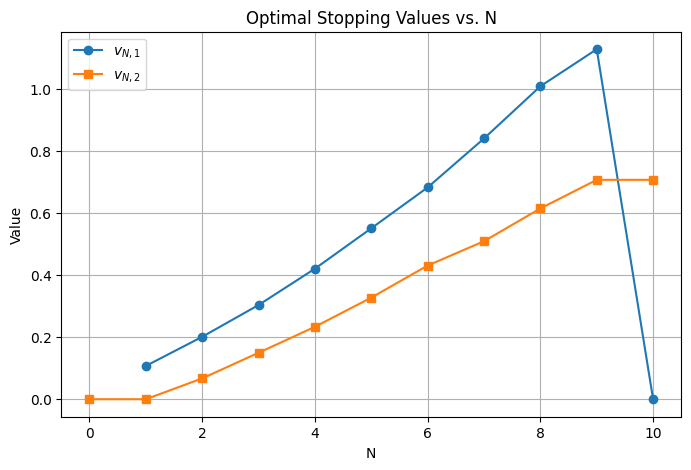

In [9]:
env = GeometricRandomWalk(1, 0.2, 2, 10)
r = 0.8
agent = DoubleOptimalStopping(env)
agent.plot()

In [10]:
print(agent.vN_1)
print(np.array([r ** (11 - i) for i in range(10)]))
print(r**10)
print(env.exp_max(9, r**10))

[      -inf 0.10737418 0.20142246 0.30404097 0.42123478 0.55161509
 0.68350554 0.84152774 1.01000885 1.1296085  0.        ]
[0.08589935 0.10737418 0.13421773 0.16777216 0.2097152  0.262144
 0.32768    0.4096     0.512      0.64      ]
0.10737418240000006
0.20142245744172088
